BEM参考解

=== 多核 BEM 求解无限域受压圆孔问题 ===
孔径 a=1.0m, 外边界 L=80.0m, 内压 P0=1.0e+06Pa, E=1.0e+09Pa, nu=0.3
边界单元数: 外边界=40, 内圆孔=180, 总计=220
组装系统矩阵...
矩阵组装耗时: 1.630 s
求解线性方程组...
提取近场物理场与有限差分应力...
数据提取完成，耗时: 1.234 s


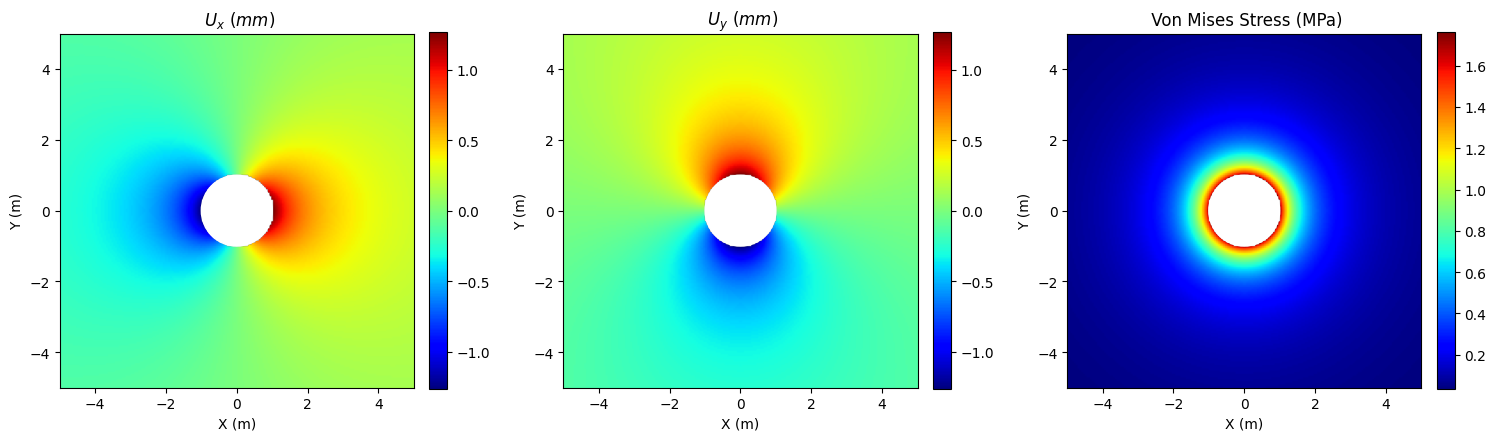

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数 (严格对齐论文截图)
# ==========================================
a = 1.0              # 圆孔半径 (m), 直径为 2a
P0 = 1.0e6           # 圆孔内压 (1 MPa)
E = 1.0e9            # 杨氏模量 (1.0 GPa)
nu = 0.3             # 泊松比

# 论文设定：外边界边长为直径的 40 倍 -> 40 * 2a = 80a
L_out = 80.0 * a     

nu_eff = nu          # 平面应变假设
G_shear = E / (2.0 * (1.0 + nu))

print(f"=== 多核 BEM 求解无限域受压圆孔问题 ===")
print(f"孔径 a={a}m, 外边界 L={L_out}m, 内压 P0={P0:.1e}Pa, E={E:.1e}Pa, nu={nu}")

def analytical_solution(x, y):
    """用于给外边界施加精确位移条件的解析解"""
    r2 = x**2 + y**2
    r = np.sqrt(r2)
    ur = (P0 * a**2) / (2 * G_shear * r)
    ux = ur * (x / r)
    uy = ur * (y / r)
    return ux, uy

# ==========================================
# 2. 生成多连通域边界网格 (外方内圆)
# ==========================================
# 论文设定：内圆孔 180 个单元，外边界 40 个单元(每边10个)
N_hole = 180  
N_side = 10   
N = N_side * 4 + N_hole

nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
is_hole = np.zeros(N, dtype=bool)

idx = 0
# 2.1 外边界 (逆时针 CCW，保证计算域在左侧，法向朝外)
coords = np.linspace(-L_out/2, L_out/2, N_side + 1)
for i in range(N_side): # 底边
    nodes[idx] = [(coords[i]+coords[i+1])/2, -L_out/2]; normals[idx] = [0, -1]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 右边
    nodes[idx] = [L_out/2, (coords[i]+coords[i+1])/2]; normals[idx] = [1, 0]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 顶边 (反向)
    nodes[idx] = [(coords[N_side-i]+coords[N_side-i-1])/2, L_out/2]; normals[idx] = [0, 1]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1
for i in range(N_side): # 左边 (反向)
    nodes[idx] = [-L_out/2, (coords[N_side-i]+coords[N_side-i-1])/2]; normals[idx] = [-1, 0]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1

# 2.2 内圆孔 (顺时针 CW，计算域在左侧，法向指向圆心)
theta = np.linspace(0, 2*np.pi, N_hole + 1)
for i in range(N_hole):
    th1 = theta[N_hole - i]      
    th2 = theta[N_hole - i - 1]
    x1, y1 = a * np.cos(th1), a * np.sin(th1)
    x2, y2 = a * np.cos(th2), a * np.sin(th2)
    th_mid = (th1 + th2) / 2
    
    nodes[idx] = [(x1+x2)/2, (y1+y2)/2]
    normals[idx] = [-np.cos(th_mid), -np.sin(th_mid)] # 法向指向圆心
    lengths[idx] = np.sqrt((x2-x1)**2 + (y2-y1)**2)
    is_hole[idx] = True
    idx += 1

# Numba 常数项
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

print(f"边界单元数: 外边界={N_side*4}, 内圆孔={N_hole}, 总计={N}")

# ==========================================
# 3. Numba 核心积分引擎
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            r0, r1 = 2*i, 2*i+1
            c0, c1 = 2*j, 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                G[r0, c0] = tx*(g00*tx) + nx*(g11*nx); G[r0, c1] = tx*(g00*ty) + nx*(g11*ny)
                G[r1, c0] = ty*(g00*tx) + ny*(g11*nx); G[r1, c1] = ty*(g00*ty) + ny*(g11*ny)
            else:
                y_center = nodes[j]
                H00 = H01 = H10 = H11 = 0.0
                G00 = G01 = G10 = G11 = 0.0
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    rx = y_gpx - x_source[0]; ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    rdx = rx/r; rdy = ry/r
                    dr_dn = rdx*nx + rdy*ny
                    log_1_r = np.log(1.0/r)
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01; H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01; G[r1, c0] = G10; G[r1, c1] = G11
    return H, G

t0 = time.time()
print("组装系统矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"矩阵组装耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件并求解
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    dof_x, dof_y = 2*i, 2*i+1
    if is_hole[i]:
        # 圆孔边界受均匀内压 P0，法向指向圆心
        t_known[dof_x] = True; t_val[dof_x] = -P0 * normals[i, 0]
        t_known[dof_y] = True; t_val[dof_y] = -P0 * normals[i, 1]
    else:
        # 外边界施加位移解析解以模拟无限大平面
        ux_ana, uy_ana = analytical_solution(nodes[i,0], nodes[i,1])
        u_known[dof_x] = True; u_val[dof_x] = ux_ana
        u_known[dof_y] = True; u_val[dof_y] = uy_ana

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]; B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]; B += G[:, k] * t_val[k]

print("求解线性方程组...")
X = np.linalg.solve(A, B)

u_bnd = np.where(u_known, u_val, X)
t_bnd = np.where(u_known, X, t_val)

# ==========================================
# 5. 提取观测区域内场数据 (-5 到 5)
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts, N = pts.shape[0], nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x, xi_y = pts[q, 0], pts[q, 1]
        u_x = u_y = 0.0
        for j in range(N):
            y_center = nodes[j]; L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]; tx, ty = -ny, nx
            U00=U01=U10=U11=T00=T01=T10=T11=0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx/r; rdy = ry/r
                dr_dn = rdx*nx + rdy*ny; log_1_r = np.log(1.0/r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw; U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x, uj_y = u_bnd[2*j], u_bnd[2*j+1]
            tj_x, tj_y = t_bnd[2*j], t_bnd[2*j+1]
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
    return u_out

print("提取近场物理场与有限差分应力...")
# 观测区域：修改为 [-5, 5]
L_plot = 5.0 * a
grid_size = 200 # 为保证图片分辨率平滑，网格稍微加密到200x200
coords_1d = np.linspace(-L_plot, L_plot, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts_raw = np.c_[XX.ravel(), YY.ravel()]

# 核心逻辑：只计算圆孔外部的点，内部填 NaN
r_pts = np.sqrt(internal_pts_raw[:,0]**2 + internal_pts_raw[:,1]**2)
valid_mask = (r_pts > a * 1.02) # 为了避免边界奇异性，往外退一点点
internal_pts = internal_pts_raw[valid_mask]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

# 中心差分求应变与应力
eps = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps); du_dy = (u_py - u_my) / (2*eps)
eps_xx = du_dx[:, 0]; eps_yy = du_dy[:, 1]; eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy
sig_zz = nu * (sig_xx + sig_yy)

von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + (sig_yy - sig_zz)**2 + (sig_zz - sig_xx)**2) + 3 * sig_xy**2)

# 将有效数据映射回全网格
U_X_map = np.full(grid_size*grid_size, np.nan)
U_X_map[valid_mask] = u_int[:, 0]

U_Y_map = np.full(grid_size*grid_size, np.nan)
U_Y_map[valid_mask] = u_int[:, 1]

VM_map = np.full(grid_size*grid_size, np.nan)
VM_map[valid_mask] = von_mises

print(f"数据提取完成，耗时: {time.time()-t2:.3f} s")

# ==========================================
# 6. 绘图出图 (Ux, Uy 单位改为 mm, Von Mises 为 MPa)
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 5))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)
extent = [-L_plot, L_plot, -L_plot, L_plot]

# 子图 1: Ux 方向位移 (单位: mm)
ax0 = fig.add_subplot(gs[0, 0])
# 1e3 将 m 转换为 mm
im0 = ax0.imshow(U_X_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title(' $U_x$ ($mm$)')
ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True)) # 遮盖孔洞

# 子图 2: Uy 方向位移 (单位: mm)
ax1 = fig.add_subplot(gs[0, 1])
# 1e3 将 m 转换为 mm
im1 = ax1.imshow(U_Y_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title(' $U_y$ ($mm$)')
ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

# 子图 3: Von Mises 应力 (单位: MPa)
ax2 = fig.add_subplot(gs[0, 2])
# 1e-6 将 Pa 转换为 MPa
im2 = ax2.imshow(VM_map.reshape(grid_size, grid_size)/1e6, origin='lower', extent=extent, cmap='jet')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title(' Von Mises Stress (MPa)')
ax2.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

plt.show()

KM-PIKFNN 点力基本解法



=== KM-PIKFNN 求解无限大平面受压圆孔问题 ===
归一化参数: E* = 1000.0, P0* = 1.0, G* = 384.615
Source distribution: 64 hole interior sources + 96 outer sources = 160 total; 360 hole boundary points + 640 outer boundary points.


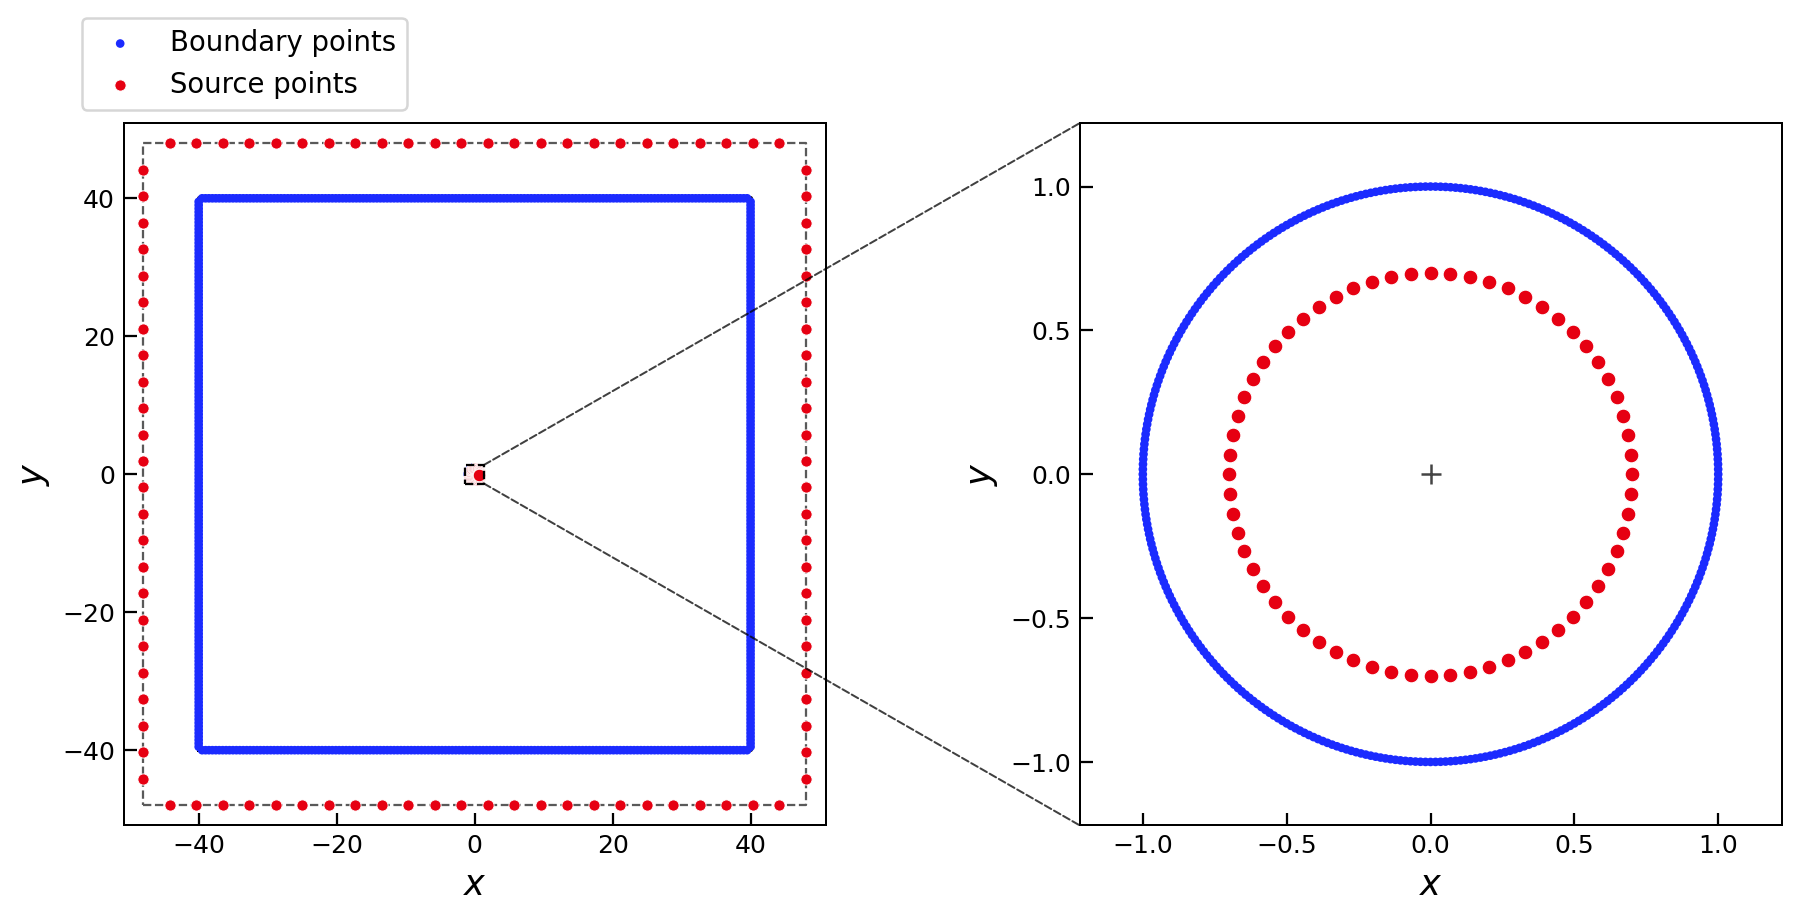

KM-PIKFNN basis: hole sources=64, outer sources=96, total=160
  KM-PIKFNN LS warm start assembly: rows=2000, unknowns=328
  KM-PIKFNN LS init | rank=326 | rms=4.4947e-09 | max=1.0966e-08 | cond~=3.1249e+17
--- Adam fine-tune from LS init (500 epochs) ---
Adam Epoch    0 | Loss: 5.5567e-13
Adam Epoch  100 | Loss: 4.4514e-07
Adam Epoch  200 | Loss: 3.7207e-09
Adam Epoch  300 | Loss: 1.8609e-09
Adam Epoch  400 | Loss: 1.0166e-09
Adam Epoch  499 | Loss: 6.0529e-10

--- L-BFGS fine-tune from current state (max_iter=1200) ---
L-BFGS 完成 | 最终 Loss: 6.0225e-10
训练总耗时: 25.25 s


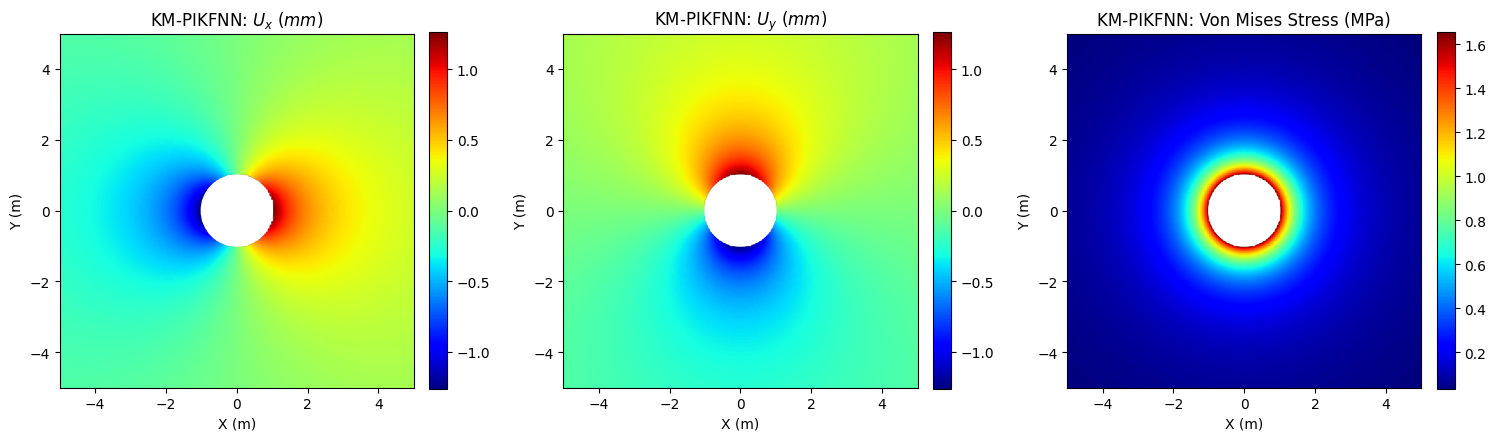

In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# ==========================================
# 1. 物理参数与量纲归一化
# ==========================================
a = 1.0              # 圆孔半径 (m)
P0_real = 1.0e6      # 圆孔内压 (1 MPa)
E_real = 1.0e9       # 杨氏模量 (1.0 GPa)
nu = 0.3             # 泊松比
L_out = 80.0 * a     # 虚拟无限远外边界边长

# 【量纲归一化】
stress_scale = 1.0e6
P0 = P0_real / stress_scale   # 1.0
E = E_real / stress_scale     # 1000.0

kappa = 3.0 - 4.0 * nu
G = E / (2.0 * (1.0 + nu))

SOURCE_SCALE = 1.2
SOURCE_OFFSET = 0.5 * (SOURCE_SCALE - 1.0) * L_out
HOLE_SOURCE_SCALE = 0.70
N_HOLE_SOURCES = 64
N_HOLE_BND = 360
N_OUT_BND = 160

print(f"=== KM-PIKFNN 求解无限大平面受压圆孔问题 ===")
print(f"归一化参数: E* = {E}, P0* = {P0}, G* = {G:.3f}")

# ==========================================
# 2. 内外源点与 KM 复势核函数网络
# ==========================================
def build_source_points(
    n_sources_per_side=24,
    source_offset=SOURCE_OFFSET,
    n_hole_sources=N_HOLE_SOURCES,
    hole_source_scale=HOLE_SOURCE_SCALE,
):
    """生成圆孔内部源点环与外方形外部源点环。"""
    hole_radius = float(hole_source_scale) * a
    theta = np.linspace(
        0.0, 2.0 * np.pi, int(n_hole_sources), endpoint=False,
        dtype=np.float32
    )
    hole_sources = np.column_stack([
        hole_radius * np.cos(theta),
        hole_radius * np.sin(theta),
    ])

    offset = float(source_offset)
    half_len = 0.5 * L_out + offset
    lo_x, hi_x = -half_len, half_len
    lo_y, hi_y = -half_len, half_len

    t_x = np.linspace(lo_x, hi_x, n_sources_per_side + 2, dtype=np.float32)[1:-1]
    t_y = np.linspace(lo_y, hi_y, n_sources_per_side + 2, dtype=np.float32)[1:-1]

    bottom = np.column_stack([t_x, np.full_like(t_x, lo_y)])
    right = np.column_stack([np.full_like(t_y, hi_x), t_y])
    top = np.column_stack([t_x[::-1], np.full_like(t_x, hi_y)])
    left = np.column_stack([np.full_like(t_y, lo_x), t_y[::-1]])
    outer_sources = np.vstack([bottom, right, top, left])

    return np.vstack([hole_sources, outer_sources]).astype(np.float32)


def split_source_points(source_points, n_hole_sources=N_HOLE_SOURCES):
    """将总源点数组分成圆孔内部源点和外部方形源点。"""
    n_hole_sources = int(n_hole_sources)
    return source_points[:n_hole_sources], source_points[n_hole_sources:]



def build_branch_angles(source_x, source_y, n_hole_sources=N_HOLE_SOURCES):
    """Return the log-branch rotation used by both torch and NumPy kernels."""
    n_hole_sources = int(n_hole_sources)
    if torch.is_tensor(source_x):
        theta = torch.empty_like(source_x)
        n_total = int(source_x.numel())
        if n_hole_sources > 0:
            # Hole sources use an outward positive axis, so the atan2 branch cut
            # is directed mostly through the excluded hole.
            theta[:n_hole_sources] = torch.atan2(
                source_y[:n_hole_sources], source_x[:n_hole_sources]
            )
        if n_hole_sources < n_total:
            # Outer sources use a positive axis pointing to the physical domain,
            # so the branch cut points away from the body.
            theta[n_hole_sources:] = torch.atan2(
                -source_y[n_hole_sources:], -source_x[n_hole_sources:]
            )
        return theta

    sx = np.asarray(source_x, dtype=float)
    sy = np.asarray(source_y, dtype=float)
    theta = np.empty_like(sx, dtype=float)
    n_total = int(theta.size)
    if n_hole_sources > 0:
        theta[:n_hole_sources] = np.arctan2(
            sy[:n_hole_sources], sx[:n_hole_sources]
        )
    if n_hole_sources < n_total:
        theta[n_hole_sources:] = np.arctan2(
            -sy[n_hole_sources:], -sx[n_hole_sources:]
        )
    return theta


def plot_source_boundary_points(
    n_sources_per_side=24,
    n_hole_sources=N_HOLE_SOURCES,
    n_hole=360,
    n_out=160,
    source_offset=SOURCE_OFFSET,
    hole_source_scale=HOLE_SOURCE_SCALE,
):
    """绘制外方形源点、圆孔内部源点，并放大显示圆孔区域。"""
    from matplotlib.patches import ConnectionPatch

    half_len = 0.5 * L_out
    t = np.linspace(-half_len, half_len, n_out + 2, dtype=np.float32)[1:-1]
    outer_boundary = np.vstack([
        np.column_stack([t, np.full_like(t, -half_len)]),
        np.column_stack([np.full_like(t, half_len), t]),
        np.column_stack([t[::-1], np.full_like(t, half_len)]),
        np.column_stack([np.full_like(t, -half_len), t[::-1]]),
    ])

    theta = np.linspace(
        0.0, 2.0 * np.pi, n_hole, endpoint=False, dtype=np.float32
    )
    hole_boundary = np.column_stack([a * np.cos(theta), a * np.sin(theta)])

    source_points = build_source_points(
        n_sources_per_side=n_sources_per_side,
        source_offset=source_offset,
        n_hole_sources=n_hole_sources,
        hole_source_scale=hole_source_scale,
    )
    hole_source_points, outer_source_points = split_source_points(
        source_points, n_hole_sources
    )

    source_half_len = 0.5 * L_out + float(source_offset)
    physical_square = np.array([
        [-half_len, -half_len],
        [half_len, -half_len],
        [half_len, half_len],
        [-half_len, half_len],
        [-half_len, -half_len],
    ])
    source_square = np.array([
        [-source_half_len, -source_half_len],
        [source_half_len, -source_half_len],
        [source_half_len, source_half_len],
        [-source_half_len, source_half_len],
        [-source_half_len, -source_half_len],
    ])

    fig = plt.figure(figsize=(11.0, 5.2), dpi=180)
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.08], wspace=0.13)
    ax = fig.add_subplot(gs[0, 0])
    ax_zoom = fig.add_subplot(gs[0, 1])

    source_color = "#E60012"
    boundary_color = "#1B2BFF"

    ax.plot(
        physical_square[:, 0], physical_square[:, 1],
        color="black", linewidth=1.5, zorder=1
    )
    ax.plot(
        source_square[:, 0], source_square[:, 1],
        color="black", linewidth=0.9, linestyle="--", alpha=0.65, zorder=1
    )
    ax.scatter(
        outer_boundary[:, 0], outer_boundary[:, 1],
        s=12, color=boundary_color, edgecolors="none",
        label="Boundary points", zorder=3
    )
    ax.scatter(
        outer_source_points[:, 0], outer_source_points[:, 1],
        s=20, color=source_color, edgecolors="white", linewidths=0.35,
        label="Source points", zorder=4
    )
    ax.scatter(
        hole_boundary[:, 0], hole_boundary[:, 1],
        s=10, color=boundary_color, edgecolors="none", zorder=4
    )
    ax.scatter(
        hole_source_points[:, 0], hole_source_points[:, 1],
        s=25, color=source_color, edgecolors="white", linewidths=0.35,
        zorder=5
    )

    zoom_box_half = 1.35 * a
    zoom_box_x = [-zoom_box_half, zoom_box_half, zoom_box_half, -zoom_box_half, -zoom_box_half]
    zoom_box_y = [-zoom_box_half, -zoom_box_half, zoom_box_half, zoom_box_half, -zoom_box_half]
    ax.plot(
        zoom_box_x, zoom_box_y,
        color="black", linestyle="--", linewidth=0.9, zorder=6
    )

    ax_zoom.plot(
        hole_boundary[:, 0], hole_boundary[:, 1],
        color="#E91E63", linewidth=1.2, zorder=1
    )
    ax_zoom.scatter(
        hole_boundary[:, 0], hole_boundary[:, 1],
        s=12, color=boundary_color, edgecolors="none",
        label="Boundary points", zorder=3
    )
    ax_zoom.scatter(
        hole_source_points[:, 0], hole_source_points[:, 1],
        s=35, color=source_color, edgecolors="white", linewidths=0.45,
        label="Source points", zorder=4
    )
    ax_zoom.plot(
        [0.0], [0.0], marker="+", markersize=8,
        color="#444444", linestyle="None", zorder=5
    )
    zoom_half = 1.22 * a
    for xy_global, xy_zoom in [
        ((zoom_box_half, zoom_box_half), (-zoom_half, zoom_half)),   
        ((zoom_box_half, -zoom_box_half), (-zoom_half, -zoom_half)), 
    ]:
        con = ConnectionPatch(
            xyA=xy_global, coordsA=ax.transData,
            xyB=xy_zoom, coordsB=ax_zoom.transData,
            color="black", linestyle="--", linewidth=0.8, alpha=0.75
        )
        fig.add_artist(con)

    plot_half_len = source_half_len * 1.06
    ax.set_xlim(-plot_half_len, plot_half_len)
    ax.set_ylim(-plot_half_len, plot_half_len)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x$", fontsize=14)
    ax.set_ylabel(r"$y$", fontsize=14)
    ax.tick_params(axis="both", which="major", direction="in", length=5, width=0.9, labelsize=10)

    ax_zoom.set_xlim(-zoom_half, zoom_half)
    ax_zoom.set_ylim(-zoom_half, zoom_half)
    ax_zoom.set_aspect("equal", adjustable="box")
    ax_zoom.set_xlabel(r"$x$", fontsize=14)
    ax_zoom.set_ylabel(r"$y$", fontsize=14)
    ax_zoom.tick_params(axis="both", which="major", direction="in", length=5, width=0.9, labelsize=10)

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="lower left", bbox_to_anchor=(0.07, 0.88),
        frameon=True, edgecolor="#CCCCCC", fontsize=11
    )
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.13, top=0.88)

    print(
        f"Source distribution: {len(hole_source_points)} hole interior sources + "
        f"{len(outer_source_points)} outer sources = {len(source_points)} total; "
        f"{len(hole_boundary)} hole boundary points + "
        f"{len(outer_boundary)} outer boundary points."
    )
    plt.show()
    return fig, (ax, ax_zoom)


class CVNN(nn.Module):
    """KM 复势点力基本解网络。

    源点由圆孔内部源点环和外方形外部源点环共同组成。
    每个源点 zeta_j 对应一个复点力 P_j = F_xj + iF_yj，
    由该点力同时耦合决定 Phi_j 与 Psi_j。
    """
    def __init__(
        self,
        n_sources_per_side=24,
        source_offset=SOURCE_OFFSET,
        n_hole_sources=N_HOLE_SOURCES,
        hole_source_scale=HOLE_SOURCE_SCALE,
    ):
        super().__init__()
        source_pts = build_source_points(
            n_sources_per_side=n_sources_per_side,
            source_offset=source_offset,
            n_hole_sources=n_hole_sources,
            hole_source_scale=hole_source_scale,
        )
        source_x = torch.tensor(source_pts[:, 0], dtype=torch.float32)
        source_y = torch.tensor(source_pts[:, 1], dtype=torch.float32)

        theta = build_branch_angles(source_x, source_y, n_hole_sources)

        self.n_sources_per_side = int(n_sources_per_side)
        self.source_offset = float(source_offset)
        self.n_hole_sources = int(n_hole_sources)
        self.hole_source_scale = float(hole_source_scale)
        self.n_basis = int(source_x.numel())
        self.n_outer_sources = self.n_basis - self.n_hole_sources
        self.register_buffer("source_x", source_x.view(1, -1))
        self.register_buffer("source_y", source_y.view(1, -1))
        self.register_buffer("rot_cos", torch.cos(theta).view(1, -1))
        self.register_buffer("rot_sin", torch.sin(theta).view(1, -1))
        self.register_buffer("branch_angle", theta.view(1, -1))

        weight_scale = 1.0e-2 / np.sqrt(self.n_basis)
        self.w_force_re = nn.Parameter(weight_scale * torch.randn(self.n_basis, 1))
        self.w_force_im = nn.Parameter(weight_scale * torch.randn(self.n_basis, 1))

        # 规则补充项：常数项与一次项
        self.affine_phi = nn.Parameter(torch.zeros(2, 2))
        self.affine_psi = nn.Parameter(torch.zeros(2, 2))

    @staticmethod
    def _add_affine(out_re, out_im, affine, x, y):
        c_re, c_im = affine[0, 0], affine[0, 1]
        a_re, a_im = affine[1, 0], affine[1, 1]
        out_re = out_re + c_re + a_re * x - a_im * y
        out_im = out_im + c_im + a_re * y + a_im * x
        return out_re, out_im

    def forward(self, x, y):
        x_col = x.reshape(-1, 1)
        y_col = y.reshape(-1, 1)
        q_re = x_col - self.source_x
        q_im = y_col - self.source_y

        w_re = self.rot_cos * q_re + self.rot_sin * q_im
        w_im = self.rot_cos * q_im - self.rot_sin * q_re

        scale = np.sqrt(self.n_basis)
        r2 = torch.clamp(q_re.square() + q_im.square(), min=1.0e-30)
        log_q_re = 0.5 * torch.log(r2) / scale
        log_q_im = (torch.atan2(w_im, w_re) + self.branch_angle) / scale

        inv_r2 = 1.0 / r2
        inv_q_re = q_re * inv_r2 / scale
        inv_q_im = -q_im * inv_r2 / scale

        cf = 1.0 / (2.0 * np.pi * (float(kappa) + 1.0))

        # Phi = -P / [2*pi*(kappa+1)] * log(q)
        p_log_re = log_q_re @ self.w_force_re - log_q_im @ self.w_force_im
        p_log_im = log_q_re @ self.w_force_im + log_q_im @ self.w_force_re
        phi_R = -cf * p_log_re
        phi_I = -cf * p_log_im

        # Psi = [kappa*conj(P) log(q) + P*conj(zeta)/q] / [2*pi*(kappa+1)]
        pbar_log_re = log_q_re @ self.w_force_re + log_q_im @ self.w_force_im
        pbar_log_im = -log_q_re @ self.w_force_im + log_q_im @ self.w_force_re

        zeta_bar_re = self.source_x
        zeta_bar_im = -self.source_y
        zeta_bar_over_q_re = zeta_bar_re * inv_q_re - zeta_bar_im * inv_q_im
        zeta_bar_over_q_im = zeta_bar_re * inv_q_im + zeta_bar_im * inv_q_re

        p_zeta_bar_over_q_re = zeta_bar_over_q_re @ self.w_force_re - zeta_bar_over_q_im @ self.w_force_im
        p_zeta_bar_over_q_im = zeta_bar_over_q_re @ self.w_force_im + zeta_bar_over_q_im @ self.w_force_re

        psi_R = cf * (float(kappa) * pbar_log_re + p_zeta_bar_over_q_re)
        psi_I = cf * (float(kappa) * pbar_log_im + p_zeta_bar_over_q_im)

        phi_R, phi_I = self._add_affine(phi_R, phi_I, self.affine_phi, x_col, y_col)
        psi_R, psi_I = self._add_affine(psi_R, psi_I, self.affine_psi, x_col, y_col)
        return phi_R.reshape_as(x), phi_I.reshape_as(x), psi_R.reshape_as(x), psi_I.reshape_as(x)


# ==========================================
# 3. 核心物理场求导引擎
# ==========================================
def get_phys_fields(model, x, y):
    phi_R, phi_I, psi_R, psi_I = model(x, y)

    dphi_dx_R = torch.autograd.grad(phi_R, x, grad_outputs=torch.ones_like(phi_R), create_graph=True)[0]
    dphi_dx_I = torch.autograd.grad(phi_I, x, grad_outputs=torch.ones_like(phi_I), create_graph=True)[0]
    dpsi_dx_R = torch.autograd.grad(psi_R, x, grad_outputs=torch.ones_like(psi_R), create_graph=True)[0]
    dpsi_dx_I = torch.autograd.grad(psi_I, x, grad_outputs=torch.ones_like(psi_I), create_graph=True)[0]

    d2phi_dx2_R = torch.autograd.grad(dphi_dx_R, x, grad_outputs=torch.ones_like(dphi_dx_R), create_graph=True)[0]
    d2phi_dx2_I = torch.autograd.grad(dphi_dx_I, x, grad_outputs=torch.ones_like(dphi_dx_I), create_graph=True)[0]

    kappa_f = float(kappa)
    G_f = float(G)

    # 2G(u_x+i*u_y) = kappa*Phi - z*conj(Phi') - conj(Psi)
    z_conj_dphi_R = x * dphi_dx_R + y * dphi_dx_I
    z_conj_dphi_I = y * dphi_dx_R - x * dphi_dx_I
    u_x = (kappa_f * phi_R - z_conj_dphi_R - psi_R) / (2.0 * G_f)
    u_y = (kappa_f * phi_I - z_conj_dphi_I + psi_I) / (2.0 * G_f)

    # sigma_xx + sigma_yy = 4 Re(Phi')
    # sigma_yy - sigma_xx + 2i*sigma_xy = 2(conj(z)*Phi'' + Psi')
    sum_sig = 4.0 * dphi_dx_R
    diff_R = 2.0 * (x * d2phi_dx2_R + y * d2phi_dx2_I + dpsi_dx_R)
    diff_I = 2.0 * (x * d2phi_dx2_I - y * d2phi_dx2_R + dpsi_dx_I)

    sig_xx = (sum_sig - diff_R) / 2.0
    sig_yy = (sum_sig + diff_R) / 2.0
    sig_xy = diff_I / 2.0

    return u_x, u_y, sig_xx, sig_yy, sig_xy

# ==========================================
# 4. 边界条件采样与损失函数 (圆孔与无限远边界)
# ==========================================
def _boundary_tensors(n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    theta = torch.linspace(0.0, 2.0 * np.pi, int(n_hole) + 1, dtype=torch.float32)[:-1].view(-1, 1)
    x_hole = (a * torch.cos(theta)).requires_grad_(True)
    y_hole = (a * torch.sin(theta)).requires_grad_(True)

    coords = torch.linspace(-L_out / 2.0, L_out / 2.0, int(n_out) + 2, dtype=torch.float32)[1:-1].view(-1, 1)
    half_L = torch.full_like(coords, L_out / 2.0)
    outer = {
        "top": (coords.clone(), half_L.clone()),
        "bottom": (coords.clone(), -half_L.clone()),
        "right": (half_L.clone(), coords.clone()),
        "left": (-half_L.clone(), coords.clone()),
    }
    return x_hole, y_hole, outer


def get_bnd_loss(case_model, n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    x_hole, y_hole, outer = _boundary_tensors(n_hole, n_out)

    _, _, sig_xx, sig_yy, sig_xy = get_phys_fields(case_model, x_hole, y_hole)
    cos2 = (x_hole**2 - y_hole**2) / (a**2)
    sin2 = (2.0 * x_hole * y_hole) / (a**2)
    sig_rr = 0.5 * (sig_xx + sig_yy) + 0.5 * (sig_xx - sig_yy) * cos2 + sig_xy * sin2
    sig_rt = -0.5 * (sig_xx - sig_yy) * sin2 + sig_xy * cos2
    loss_hole = torch.mean((sig_rr + P0)**2 + sig_rt**2)

    def outer_loss(x_val, y_val):
        x = x_val.clone().detach().requires_grad_(True)
        y = y_val.clone().detach().requires_grad_(True)
        ux_pred, uy_pred, _, _, _ = get_phys_fields(case_model, x, y)
        r2 = x**2 + y**2
        ux_exact = (P0 * a**2 * x) / (2.0 * G * r2)
        uy_exact = (P0 * a**2 * y) / (2.0 * G * r2)
        return torch.mean(((ux_pred - ux_exact) * (2.0 * G))**2 + ((uy_pred - uy_exact) * (2.0 * G))**2)

    loss_outer = sum(outer_loss(x, y) for x, y in outer.values())
    return loss_hole + loss_outer


# --- Least-squares warm start, following the square-plate KM-FSNet code style. ---
def _kmfs_as_complex(points):
    points = np.asarray(points, dtype=float)
    return points[:, 0] + 1j * points[:, 1]


def _kmfs_coefficient_count(n_basis):
    return 2 * int(n_basis) + 8


def _kmfs_unpack_coeffs(coeffs, n_basis):
    coeffs = np.asarray(coeffs, dtype=float)
    n = int(n_basis)
    idx = 0
    point_force = coeffs[idx:idx+n] + 1j * coeffs[idx+n:idx+2*n]
    idx += 2 * n
    phi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    phi1 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi1 = coeffs[idx] + 1j * coeffs[idx+1]
    return point_force, phi0, phi1, psi0, psi1


def _kmfs_prepare_cache(points, source_points, n_hole_sources=N_HOLE_SOURCES):
    z = _kmfs_as_complex(points)
    src_c = _kmfs_as_complex(source_points)
    dz = z[:, None] - src_c[None, :]
    branch_angle = build_branch_angles(src_c.real, src_c.imag, n_hole_sources)
    rotated = dz * np.exp(-1j * branch_angle[None, :])

    n_basis = len(src_c)
    scale = np.sqrt(n_basis)
    basis = (
        np.log(np.maximum(np.abs(rotated), 1.0e-300))
        + 1j * (np.angle(rotated) + branch_angle[None, :])
    ) / scale
    d1 = (1.0 / dz) / scale
    d2 = (-1.0 / (dz * dz)) / scale
    return {
        "z": z,
        "basis": basis,
        "d1": d1,
        "d2": d2,
        "zeta_bar": np.conj(src_c),
        "n_basis": n_basis,
    }


def _kmfs_fields_from_coeffs(coeffs, cache):
    z = cache["z"]
    basis = cache["basis"]
    d1 = cache["d1"]
    d2 = cache["d2"]
    zeta_bar = cache["zeta_bar"]
    n_basis = cache["n_basis"]
    point_force, phi0, phi1, psi0, psi1 = _kmfs_unpack_coeffs(coeffs, n_basis)

    cf = 1.0 / (2.0 * np.pi * (float(kappa) + 1.0))
    phi = -cf * (basis @ point_force) + phi0 + phi1 * z
    dphi = -cf * (d1 @ point_force) + phi1
    d2phi = -cf * (d2 @ point_force)

    psi = cf * (
        float(kappa) * (basis @ np.conj(point_force))
        + (d1 * zeta_bar[None, :]) @ point_force
    ) + psi0 + psi1 * z
    dpsi = cf * (
        float(kappa) * (d1 @ np.conj(point_force))
        + (d2 * zeta_bar[None, :]) @ point_force
    ) + psi1

    disp_complex = (kappa * phi - z * np.conj(dphi) - np.conj(psi)) / (2.0 * G)
    ux = disp_complex.real
    uy = disp_complex.imag

    sum_sig = 4.0 * dphi.real
    diff = 2.0 * (np.conj(z) * d2phi + dpsi)
    sig_xx = 0.5 * (sum_sig - diff.real)
    sig_yy = 0.5 * (sum_sig + diff.real)
    sig_xy = 0.5 * diff.imag
    return ux, uy, sig_xx, sig_yy, sig_xy


def _boundary_points_numpy(n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    theta = np.linspace(0.0, 2.0 * np.pi, int(n_hole), endpoint=False, dtype=float)
    hole = np.column_stack([a * np.cos(theta), a * np.sin(theta)])

    t = np.linspace(-L_out / 2.0, L_out / 2.0, int(n_out) + 2, dtype=float)[1:-1]
    half = 0.5 * L_out
    outer = {
        "top": np.column_stack([t, np.full_like(t, half)]),
        "bottom": np.column_stack([t, np.full_like(t, -half)]),
        "right": np.column_stack([np.full_like(t, half), t]),
        "left": np.column_stack([np.full_like(t, -half), t]),
    }
    return hole, outer


def _outer_exact_displacement(points):
    x = points[:, 0]
    y = points[:, 1]
    r2 = x * x + y * y
    ux_exact = (P0 * a**2 * x) / (2.0 * G * r2)
    uy_exact = (P0 * a**2 * y) / (2.0 * G * r2)
    return ux_exact, uy_exact


def _kmfs_boundary_residual_numpy(coeffs, boundary_caches, boundary_points):
    hole_points, outer_points = boundary_points
    _, _, sxx_h, syy_h, sxy_h = _kmfs_fields_from_coeffs(coeffs, boundary_caches["hole"])
    x_h = hole_points[:, 0]
    y_h = hole_points[:, 1]
    cos2 = (x_h * x_h - y_h * y_h) / (a * a)
    sin2 = (2.0 * x_h * y_h) / (a * a)
    sig_rr = 0.5 * (sxx_h + syy_h) + 0.5 * (sxx_h - syy_h) * cos2 + sxy_h * sin2
    sig_rt = -0.5 * (sxx_h - syy_h) * sin2 + sxy_h * cos2

    residuals = [sig_rr + P0, sig_rt]
    for name in ("top", "bottom", "right", "left"):
        ux, uy, _, _, _ = _kmfs_fields_from_coeffs(coeffs, boundary_caches[name])
        ux_exact, uy_exact = _outer_exact_displacement(outer_points[name])
        residuals.extend([(ux - ux_exact) * (2.0 * G), (uy - uy_exact) * (2.0 * G)])
    return np.concatenate(residuals)


def solve_kmfsnet_output_layer_lstsq(
    n_sources_per_side=24,
    source_offset=SOURCE_OFFSET,
    n_hole_sources=N_HOLE_SOURCES,
    hole_source_scale=HOLE_SOURCE_SCALE,
    n_hole=N_HOLE_BND,
    n_out=N_OUT_BND,
    rcond=None,
    progress=True,
):
    t0 = time.time()
    source_points = build_source_points(
        n_sources_per_side=n_sources_per_side,
        source_offset=source_offset,
        n_hole_sources=n_hole_sources,
        hole_source_scale=hole_source_scale,
    ).astype(float)
    hole_points, outer_points = _boundary_points_numpy(n_hole, n_out)
    boundary_points = (hole_points, outer_points)
    boundary_caches = {"hole": _kmfs_prepare_cache(hole_points, source_points, n_hole_sources)}
    for name, points in outer_points.items():
        boundary_caches[name] = _kmfs_prepare_cache(points, source_points, n_hole_sources)

    n_unknown = _kmfs_coefficient_count(len(source_points))
    zero = np.zeros(n_unknown, dtype=float)
    r0 = _kmfs_boundary_residual_numpy(zero, boundary_caches, boundary_points)
    A = np.empty((r0.size, n_unknown), dtype=float)

    if progress:
        print(f"  KM-PIKFNN LS warm start assembly: rows={r0.size}, unknowns={n_unknown}")

    for k in range(n_unknown):
        e = np.zeros(n_unknown, dtype=float)
        e[k] = 1.0
        A[:, k] = _kmfs_boundary_residual_numpy(e, boundary_caches, boundary_points) - r0

    coeffs, residuals, rank, singular_values = np.linalg.lstsq(A, -r0, rcond=rcond)
    final_residual = _kmfs_boundary_residual_numpy(coeffs, boundary_caches, boundary_points)
    elapsed = time.time() - t0
    rms = float(np.sqrt(np.mean(final_residual**2)))
    max_abs = float(np.max(np.abs(final_residual)))
    cond_est = float(singular_values[0] / singular_values[-1]) if singular_values.size and singular_values[-1] > 0 else np.inf
    info = {
        "lstsq_rank": int(rank),
        "lstsq_boundary_rms": rms,
        "lstsq_boundary_max_abs": max_abs,
        "lstsq_condition_est": cond_est,
        "lstsq_solve_time_s": float(elapsed),
    }
    return coeffs, info


def load_kmfsnet_coeffs_into_model(model, coeffs):
    n = int(model.n_basis)
    point_force, phi0, phi1, psi0, psi1 = _kmfs_unpack_coeffs(coeffs, n)
    with torch.no_grad():
        model.w_force_re.copy_(torch.as_tensor(point_force.real.reshape(-1, 1), dtype=torch.float32))
        model.w_force_im.copy_(torch.as_tensor(point_force.imag.reshape(-1, 1), dtype=torch.float32))
        model.affine_phi.copy_(torch.as_tensor([[phi0.real, phi0.imag], [phi1.real, phi1.imag]], dtype=torch.float32))
        model.affine_psi.copy_(torch.as_tensor([[psi0.real, psi0.imag], [psi1.real, psi1.imag]], dtype=torch.float32))


# ==========================================
# 5. 训练网络 (Adam + L-BFGS)
# ==========================================
if __name__ == "__main__":
    model = CVNN(
        n_sources_per_side=24,
        source_offset=SOURCE_OFFSET,
        n_hole_sources=N_HOLE_SOURCES,
        hole_source_scale=HOLE_SOURCE_SCALE,
    )
    plot_source_boundary_points(
        n_sources_per_side=24,
        n_hole_sources=N_HOLE_SOURCES,
        n_hole=N_HOLE_BND,
        n_out=N_OUT_BND,
        source_offset=SOURCE_OFFSET,
        hole_source_scale=HOLE_SOURCE_SCALE,
    )

    print(
        f"KM-PIKFNN basis: hole sources={model.n_hole_sources}, "
        f"outer sources={model.n_outer_sources}, total={model.n_basis}"
    )
    t0 = time.time()

    coeffs, lstsq_info = solve_kmfsnet_output_layer_lstsq(
        n_sources_per_side=24,
        source_offset=SOURCE_OFFSET,
        n_hole_sources=N_HOLE_SOURCES,
        hole_source_scale=HOLE_SOURCE_SCALE,
        n_hole=N_HOLE_BND,
        n_out=N_OUT_BND,
        rcond=None,
        progress=True,
    )
    load_kmfsnet_coeffs_into_model(model, coeffs)
    print(
        "  KM-PIKFNN LS init | "
        f"rank={lstsq_info['lstsq_rank']} | "
        f"rms={lstsq_info['lstsq_boundary_rms']:.4e} | "
        f"max={lstsq_info['lstsq_boundary_max_abs']:.4e} | "
        f"cond~={lstsq_info['lstsq_condition_est']:.4e}"
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    epochs_adam = 500
    print(f"--- Adam fine-tune from LS init ({epochs_adam} epochs) ---")
    for epoch in range(epochs_adam):
        optimizer.zero_grad()
        loss = get_bnd_loss(model, N_HOLE_BND, N_OUT_BND)
        loss.backward()
        optimizer.step()
        if epoch % 100 == 0 or epoch == epochs_adam - 1:
            print(f"Adam Epoch {epoch:4d} | Loss: {loss.item():.4e}")

    lbfgs_max_iter = 1200
    lbfgs_optimizer = torch.optim.LBFGS(
        model.parameters(),
        lr=1.0,
        max_iter=lbfgs_max_iter,
        max_eval=int(lbfgs_max_iter * 1.5) + 1,
        history_size=100,
        tolerance_grad=1e-9,
        tolerance_change=1e-11,
        line_search_fn="strong_wolfe",
    )

    print(f"\n--- L-BFGS fine-tune from current state (max_iter={lbfgs_max_iter}) ---")
    iter_count = [0]

    def closure():
        lbfgs_optimizer.zero_grad()
        loss = get_bnd_loss(model, N_HOLE_BND, N_OUT_BND)
        loss.backward()
        iter_count[0] += 1
        if iter_count[0] % 200 == 0:
            print(f"L-BFGS Iter {iter_count[0]:4d} | Loss: {loss.item():.4e}")
        return loss

    lbfgs_optimizer.step(closure)
    final_loss = float(get_bnd_loss(model, N_HOLE_BND, N_OUT_BND).detach().item())
    print(f"L-BFGS 完成 | 最终 Loss: {final_loss:.4e}")
    KM_PIKFNN_TRAIN_TIME = time.time() - t0
    print(f"训练总耗时: {KM_PIKFNN_TRAIN_TIME:.2f} s")

    # ==========================================
    # 6. 全场预测与后处理提取 [-5, 5] 区域
    # ==========================================
    L_plot = 5.0 * a
    grid_size = 200
    coords_1d = np.linspace(-L_plot, L_plot, grid_size)
    XX, YY = np.meshgrid(coords_1d, coords_1d)

    r_pts = np.sqrt(XX**2 + YY**2)
    valid_mask = r_pts >= a * 1.02

    X_tensor = torch.tensor(XX[valid_mask].flatten(), dtype=torch.float32).view(-1, 1).requires_grad_(True)
    Y_tensor = torch.tensor(YY[valid_mask].flatten(), dtype=torch.float32).view(-1, 1).requires_grad_(True)

    model.eval()
    u_x_pred, u_y_pred, sig_xx_pred, sig_yy_pred, sig_xy_pred = get_phys_fields(model, X_tensor, Y_tensor)

    u_x_mm = u_x_pred.detach().numpy().flatten() * 1e3
    u_y_mm = u_y_pred.detach().numpy().flatten() * 1e3

    sig_xx_MPa = sig_xx_pred.detach().numpy().flatten()
    sig_yy_MPa = sig_yy_pred.detach().numpy().flatten()
    sig_xy_MPa = sig_xy_pred.detach().numpy().flatten()

    sig_zz_MPa = nu * (sig_xx_MPa + sig_yy_MPa)
    von_mises_MPa = np.sqrt(
        0.5 * ((sig_xx_MPa - sig_yy_MPa)**2 +
               (sig_yy_MPa - sig_zz_MPa)**2 +
               (sig_zz_MPa - sig_xx_MPa)**2) +
        3 * sig_xy_MPa**2
    )

    U_X_map = np.full((grid_size, grid_size), np.nan)
    U_X_map[valid_mask] = u_x_mm

    U_Y_map = np.full((grid_size, grid_size), np.nan)
    U_Y_map[valid_mask] = u_y_mm

    VM_map = np.full((grid_size, grid_size), np.nan)
    VM_map[valid_mask] = von_mises_MPa

    # ==========================================
    # 7. 绘图出图 (与 BEM 一一对应)
    # ==========================================
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=(18, 5))
    gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)
    extent = [-L_plot, L_plot, -L_plot, L_plot]

    ax0 = fig.add_subplot(gs[0, 0])
    im0 = ax0.imshow(U_X_map, origin='lower', extent=extent, cmap='jet')
    ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
    fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title('KM-PIKFNN: $U_x$ ($mm$)')
    ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

    ax1 = fig.add_subplot(gs[0, 1])
    im1 = ax1.imshow(U_Y_map, origin='lower', extent=extent, cmap='jet')
    ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
    ax1.set_title('KM-PIKFNN: $U_y$ ($mm$)')
    ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

    ax2 = fig.add_subplot(gs[0, 2])
    im2 = ax2.imshow(VM_map, origin='lower', extent=extent, cmap='jet')
    ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
    fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
    ax2.set_title('KM-PIKFNN: Von Mises Stress (MPa)')
    ax2.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

    plt.show()

    # Preserve common-grid predictions in SI units for the unified comparison.
    def _snapshot_grid_tensor(tensor):
        return tensor.detach().cpu().numpy().reshape(-1).copy()

    KM_GRID_UX_VALID_M = _snapshot_grid_tensor(u_x_pred)
    KM_GRID_UY_VALID_M = _snapshot_grid_tensor(u_y_pred)
    KM_GRID_SXX_VALID_PA = _snapshot_grid_tensor(sig_xx_pred) * stress_scale
    KM_GRID_SYY_VALID_PA = _snapshot_grid_tensor(sig_yy_pred) * stress_scale
    KM_GRID_SXY_VALID_PA = _snapshot_grid_tensor(sig_xy_pred) * stress_scale




=== ???? KM-PIKFNN ? BEM ????? ===
----------------------------------------------------------
Relative L2 error Ux        : 2.761e-03
Relative L2 error Uy        : 2.761e-03
Relative L2 error von Mises : 5.992e-03
Max Normalized Error Ux        : 2.810e-03
Max Normalized Error Uy        : 2.819e-03
Max Normalized Error von Mises : 6.041e-02
----------------------------------------------------------


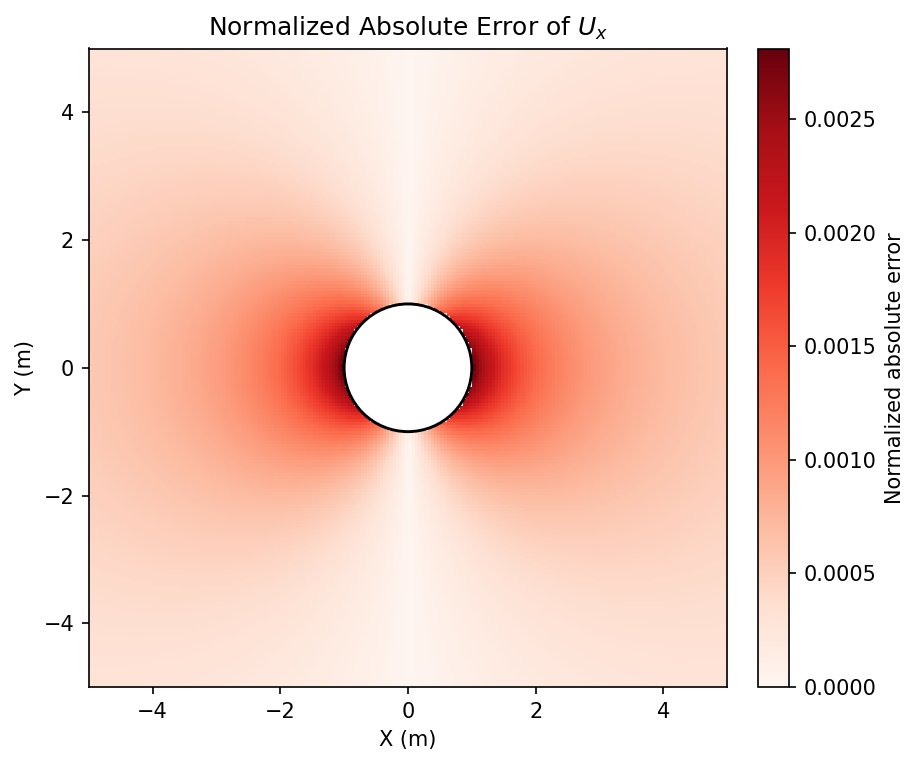

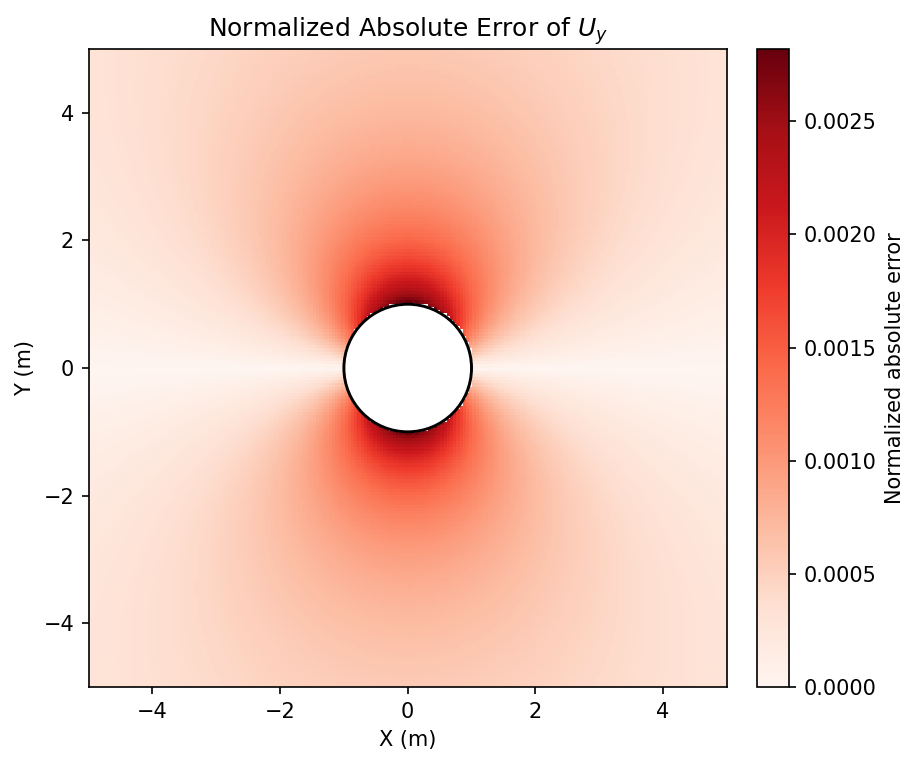

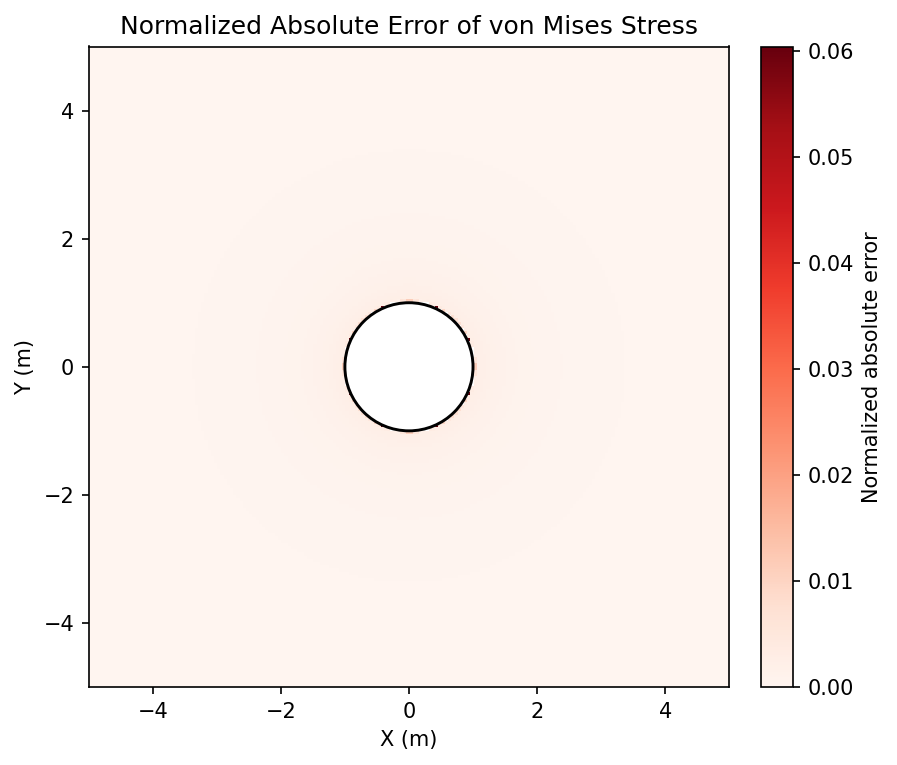

(<Figure size 930x780 with 2 Axes>,
 <Axes: title={'center': 'Normalized Absolute Error of von Mises Stress'}, xlabel='X (m)', ylabel='Y (m)'>)

In [3]:
# ==========================================
# 8. KM-PIKFNN ??? BEM ??????? von Mises ??????
# ==========================================
print("\n=== ???? KM-PIKFNN ? BEM ????? ===")

# 1. ????????????? KM ???????
# ???internal_pts?u_int ? von_mises ????? BEM ?????
if "internal_pts" not in globals() or "u_int" not in globals() or "von_mises" not in globals():
    raise NameError("???? BEM ???????? internal_pts?u_int ? von_mises ????")

X_bem = torch.tensor(internal_pts[:, 0:1], dtype=torch.float32, requires_grad=True)
Y_bem = torch.tensor(internal_pts[:, 1:2], dtype=torch.float32, requires_grad=True)

# 2. KM-PIKFNN ???????????? m????????????? stress_scale ?? Pa
model.eval()
u_pred_bem, v_pred_bem, sig_xx_pred, sig_yy_pred, sig_xy_pred = get_phys_fields(model, X_bem, Y_bem)

def _to_numpy(tensor):
    return tensor.detach().cpu().numpy().reshape(-1)

u_pred_real = _to_numpy(u_pred_bem)
v_pred_real = _to_numpy(v_pred_bem)

sig_xx_pred_real = _to_numpy(sig_xx_pred) * stress_scale
sig_yy_pred_real = _to_numpy(sig_yy_pred) * stress_scale
sig_xy_pred_real = _to_numpy(sig_xy_pred) * stress_scale
sig_zz_pred_real = nu * (sig_xx_pred_real + sig_yy_pred_real)
vm_pred_real = np.sqrt(
    0.5 * ((sig_xx_pred_real - sig_yy_pred_real)**2 +
           (sig_yy_pred_real - sig_zz_pred_real)**2 +
           (sig_zz_pred_real - sig_xx_pred_real)**2) +
    3.0 * sig_xy_pred_real**2
)

# 3. ?? BEM ?????? m?von Mises ?? Pa
u_bem_ref = np.asarray(u_int[:, 0]).reshape(-1)
v_bem_ref = np.asarray(u_int[:, 1]).reshape(-1)
vm_bem_ref = np.asarray(von_mises).reshape(-1)

n_eval = internal_pts.shape[0]
for name, arr in {
    "u_pred_real": u_pred_real,
    "v_pred_real": v_pred_real,
    "vm_pred_real": vm_pred_real,
    "u_bem_ref": u_bem_ref,
    "v_bem_ref": v_bem_ref,
    "vm_bem_ref": vm_bem_ref,
}.items():
    if arr.size != n_eval:
        raise ValueError(f"{name} ???? {arr.size}?? internal_pts ???? {n_eval}???? BEM ? KM-PIKFNN ?????????")

# 4. ???????????? L2 ??
norm_factor_ux = max(np.max(np.abs(u_bem_ref)), 1e-15)
norm_factor_uy = max(np.max(np.abs(v_bem_ref)), 1e-15)
norm_factor_vm = max(np.max(np.abs(vm_bem_ref)), 1e-15)

err_ux_norm = np.abs(u_pred_real - u_bem_ref) / norm_factor_ux
err_uy_norm = np.abs(v_pred_real - v_bem_ref) / norm_factor_uy
err_vm_norm = np.abs(vm_pred_real - vm_bem_ref) / norm_factor_vm

L2_ux = np.linalg.norm(u_pred_real - u_bem_ref, 2) / max(np.linalg.norm(u_bem_ref, 2), 1e-15)
L2_uy = np.linalg.norm(v_pred_real - v_bem_ref, 2) / max(np.linalg.norm(v_bem_ref, 2), 1e-15)
L2_vm = np.linalg.norm(vm_pred_real - vm_bem_ref, 2) / max(np.linalg.norm(vm_bem_ref, 2), 1e-15)

print("-" * 58)
print(f"Relative L2 error Ux        : {L2_ux:.3e}")
print(f"Relative L2 error Uy        : {L2_uy:.3e}")
print(f"Relative L2 error von Mises : {L2_vm:.3e}")
print(f"Max Normalized Error Ux        : {err_ux_norm.max():.3e}")
print(f"Max Normalized Error Uy        : {err_uy_norm.max():.3e}")
print(f"Max Normalized Error von Mises : {err_vm_norm.max():.3e}")
print("-" * 58)

# ==========================================
# 5. ??? 2D ?????????????????
# ==========================================
valid_mask_1d = np.asarray(valid_mask).reshape(-1)
extent = [-L_plot, L_plot, -L_plot, L_plot]

def _make_error_map(error_values):
    error_map = np.full(grid_size * grid_size, np.nan)
    error_map[valid_mask_1d] = error_values
    return error_map.reshape(grid_size, grid_size)

Err_X_map = _make_error_map(err_ux_norm)
Err_Y_map = _make_error_map(err_uy_norm)
Err_VM_map = _make_error_map(err_vm_norm)

def plot_normalized_error(error_map, title):
    fig, ax = plt.subplots(figsize=(6.2, 5.2), dpi=150)
    im = ax.imshow(error_map, origin="lower", extent=extent, cmap="Reds", vmin=0)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.add_patch(plt.Circle((0, 0), a, color="white", fill=True, zorder=3))
    ax.add_patch(plt.Circle((0, 0), a, color="black", fill=False, linewidth=1.4, zorder=4))
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Normalized absolute error")
    plt.tight_layout()
    plt.show()
    return fig, ax

plot_normalized_error(Err_X_map, "Normalized Absolute Error of $U_x$")
plot_normalized_error(Err_Y_map, "Normalized Absolute Error of $U_y$")
plot_normalized_error(Err_VM_map, "Normalized Absolute Error of von Mises Stress")


## Export full-field results for the unified comparison figure

Run this cell after all preceding cells. It writes the KM-PIKFNN fields on the common grid in SI units.


In [4]:
# ============================================================
# 9. Export KM-PIKFNN fields for the unified 3 x 3 comparison
# ============================================================
from pathlib import Path
import numpy as np

required_variables = [
    "XX", "YY", "grid_size", "valid_mask", "a", "L_plot", "model",
    "KM_GRID_UX_VALID_M", "KM_GRID_UY_VALID_M",
    "KM_GRID_SXX_VALID_PA", "KM_GRID_SYY_VALID_PA", "KM_GRID_SXY_VALID_PA",
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(
        "Please run the KM-PIKFNN training and full-field prediction cell first. "
        "Missing variables: " + ", ".join(missing_variables)
    )

grid_shape = (int(grid_size), int(grid_size))
expected_size = int(grid_size) * int(grid_size)
valid_mask_export = np.asarray(valid_mask, dtype=bool).reshape(-1)

if valid_mask_export.size != expected_size:
    raise ValueError(
        f"valid_mask has {valid_mask_export.size} entries, "
        f"but the grid requires {expected_size}."
    )


def _map_km_values(values, name):
    """Map predictions at exterior points back to the common full grid."""
    values = np.asarray(values, dtype=float).reshape(-1)
    n_valid = int(np.count_nonzero(valid_mask_export))
    if values.size != n_valid:
        raise ValueError(
            f"{name} has {values.size} entries, "
            f"but valid_mask contains {n_valid} exterior points."
        )
    full = np.full(expected_size, np.nan, dtype=float)
    full[valid_mask_export] = values
    return full.reshape(grid_shape)


# The saved snapshots use SI units: displacement in m and stress in Pa.
ux_map_si = _map_km_values(KM_GRID_UX_VALID_M, "KM_GRID_UX_VALID_M")
uy_map_si = _map_km_values(KM_GRID_UY_VALID_M, "KM_GRID_UY_VALID_M")
sxx_map_si = _map_km_values(KM_GRID_SXX_VALID_PA, "KM_GRID_SXX_VALID_PA")
syy_map_si = _map_km_values(KM_GRID_SYY_VALID_PA, "KM_GRID_SYY_VALID_PA")
sxy_map_si = _map_km_values(KM_GRID_SXY_VALID_PA, "KM_GRID_SXY_VALID_PA")

# Plane-strain von Mises stress, consistent with the BEM and PINN notebooks.
szz_map_si = nu * (sxx_map_si + syy_map_si)
vm_map_si = np.sqrt(
    0.5 * (
        (sxx_map_si - syy_map_si) ** 2
        + (syy_map_si - szz_map_si) ** 2
        + (szz_map_si - sxx_map_si) ** 2
    )
    + 3.0 * sxy_map_si ** 2
)

X_export = np.asarray(XX, dtype=float)
Y_export = np.asarray(YY, dtype=float)
if X_export.shape != grid_shape or Y_export.shape != grid_shape:
    raise ValueError(
        f"XX/YY shapes must be {grid_shape}; got {X_export.shape} and {Y_export.shape}."
    )

trainable_parameters = int(
    sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
)
training_time = (
    float(KM_PIKFNN_TRAIN_TIME)
    if "KM_PIKFNN_TRAIN_TIME" in globals()
    else np.nan
)

result_dir = Path.cwd() / "field_results"
result_dir.mkdir(parents=True, exist_ok=True)
output_file = result_dir / "km_pikfnn_fields.npz"

np.savez_compressed(
    output_file,
    X=X_export,
    Y=Y_export,
    valid_mask=valid_mask_export.reshape(grid_shape),
    ux=ux_map_si,       # m
    uy=uy_map_si,       # m
    sxx=sxx_map_si,     # Pa
    syy=syy_map_si,     # Pa
    sxy=sxy_map_si,     # Pa
    vm=vm_map_si,       # Pa
    a=float(a),
    L_plot=float(L_plot),
    grid_size=int(grid_size),
    displacement_unit="m",
    stress_unit="Pa",
    method="KM-PIKFNN",
    trainable_parameters=trainable_parameters,
    training_time_s=training_time,
    final_loss=float(final_loss) if "final_loss" in globals() else np.nan,
    source_count=int(getattr(model, "n_basis", -1)),
    hole_source_count=int(getattr(model, "n_hole_sources", -1)),
    outer_source_count=int(getattr(model, "n_outer_sources", -1)),
)

# Read the file back immediately and verify compatibility-critical fields.
with np.load(output_file) as check:
    for key in ["X", "Y", "ux", "uy", "sxx", "syy", "sxy", "vm"]:
        if check[key].shape != grid_shape:
            raise RuntimeError(
                f"Export validation failed: {key} has shape {check[key].shape}."
            )
    if check["displacement_unit"].item() != "m":
        raise RuntimeError("Unexpected displacement unit in exported file.")
    if check["stress_unit"].item() != "Pa":
        raise RuntimeError("Unexpected stress unit in exported file.")

print(f"KM-PIKFNN field data saved successfully:\n{output_file.resolve()}")
print(f"Grid: {grid_size} x {grid_size}; exterior points: {valid_mask_export.sum()}")
print(f"Trainable parameters: {trainable_parameters}")
if np.isfinite(training_time):
    print(f"Training time: {training_time:.2f} s")
print(
    "Finite ranges (SI units):\n"
    f"  ux: [{np.nanmin(ux_map_si):.6e}, {np.nanmax(ux_map_si):.6e}] m\n"
    f"  uy: [{np.nanmin(uy_map_si):.6e}, {np.nanmax(uy_map_si):.6e}] m\n"
    f"  vm: [{np.nanmin(vm_map_si):.6e}, {np.nanmax(vm_map_si):.6e}] Pa"
)


KM-PIKFNN field data saved successfully:
C:\Users\magic\Desktop\KM-PIKFNN\圆孔受压\field_results\km_pikfnn_fields.npz
Grid: 200 x 200; exterior points: 38712
Trainable parameters: 328
Training time: 28.79 s
Finite ranges (SI units):
  ux: [-1.261186e-03, 1.261218e-03] m
  uy: [-1.261227e-03, 1.261176e-03] m
  vm: [3.463975e+04, 1.654797e+06] Pa
